# ShopSphere Win-Back: Exploratory Data Analysis (EDA)
**IT2226 AI Innovation and Deep Learning Project · Progress Review 1 · Input Data**
**Owner:** Davian · **Model this EDA prepares for:** neural network (MLP) that predicts `target` (a purchase between 2024-10-01 and 2024-10-30)

## What this notebook does
EDA means getting to know the data before training a model. Every section below follows the same pattern:

> **Chart or table → Finding (what the data shows) → Decision (what I changed or will do because of it)**

| # | Section | Question it answers |
|---|---|---|
| 1 | Data quality story | What was wrong with the raw data, and did cleaning fix it? |
| 2 | Target balance | How rare are buyers? Which metrics should I use? |
| 3 | Purchase rate by feature | Which features separate buyers from non-buyers? |
| 4 | Distributions, outliers and special values | Which columns need transforming, capping or flags? |
| 5 | Relationships between features | Which features are duplicates or near-copies? |
| 6 | Hypotheses and the brief's claims | Does the data back up what staff believe? |
| 7 | Fairness and train/test checks | Is the model at risk of treating countries or ages unfairly? Is the test set like the training set? |
| 8 | Data preparation for the MLP | The final, reproducible preprocessing every decision above leads to |

**Data used:** `train_features.csv` (64,000 customers with `target`, 71 columns) built by our KNIME feature workflow, plus the raw and cleaned tables for Section 1. `test_features.csv` is only used for the train/test check in Section 7. Nothing from the prediction window (after 2024-09-30) is used as an input.

## 0. Setup
All paths come from the team's shared modules (`src/shopsphere/config.py` and `src/data_prep.py`), so this notebook runs on any teammate's laptop without edits. It needs:
- the data pack in `data/raw/` (as issued, never edited),
- the KNIME cleaned tables (`*_clean.csv`) in `data/interim/`,
- the KNIME feature tables (`train_features.csv`, `test_features.csv`, `features.csv`) in `data/processed/`.

Charts are saved as PNG files in `reports/figures/eda/` so they can go straight into the slides.

In [1]:
import os, json, warnings, logging
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap

warnings.filterwarnings("ignore")
logging.getLogger("matplotlib.font_manager").setLevel(logging.ERROR)  # quiet missing-font notices
pd.set_option("display.max_columns", 80)
pd.set_option("display.width", 160)

# ---- Paths: from the team's shared modules, never hard-coded ----------------
import sys
ROOT = Path.cwd()                         # find the project root, whether opened from the root or notebooks/
while not (ROOT / "src" / "data_prep.py").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "src"))
from shopsphere.config import DATA_RAW, DATA_INTERIM, FIGURES_DIR, CUTOFF_DATE, SEED
from data_prep import DATA_DIR, get_splits

RAW = DATA_RAW                            # original data pack
CLEAN = DATA_INTERIM                      # output of ShopSphere_Cleaning (KNIME)
FEAT = DATA_DIR                           # output of ShopSphere_Features (KNIME): data/processed
CHARTS = FIGURES_DIR / "eda"
CHARTS.mkdir(parents=True, exist_ok=True)

CUTOFF = pd.Timestamp(CUTOFF_DATE)       # last day of history (2024-09-30)
SENTINEL = 1100                           # value used for "never" in days_since_* columns

# ---- Chart style: one consistent, colour-blind-safe palette ------------------
BLUE, ORANGE, RED, GRAY, LIGHTBLUE = "#2a78d6", "#eb6834", "#e34948", "#9a9993", "#86b6ef"
INK, INK2, GRID = "#0b0b0b", "#52514e", "#e4e3df"
NONBUYER, BUYER = BLUE, ORANGE            # target 0 = blue, target 1 = orange (used everywhere)
plt.rcParams.update({
    "font.family": ["Inter", "Segoe UI", "DejaVu Sans"], "font.size": 10,
    "axes.edgecolor": GRID, "axes.labelcolor": INK2, "axes.titlesize": 12, "axes.titleweight": "bold",
    "axes.titlecolor": INK, "axes.titlelocation": "left", "xtick.color": INK2, "ytick.color": INK2,
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.color": GRID,
    "grid.linewidth": 0.8, "axes.axisbelow": True, "axes.grid.axis": "y", "figure.dpi": 110, "savefig.dpi": 200,
    "savefig.bbox": "tight", "legend.frameon": False,
})
DIVERGING = LinearSegmentedColormap.from_list("blue_gray_red", [BLUE, "#f0efec", RED])

def save(fig, name):
    """Save a chart as PNG for the slides, then show it in the notebook."""
    fig.savefig(CHARTS / f"{name}.png", facecolor="white")
    plt.show()

def rate_bars(ax, table, title, xlabel="", overall=None, order=None, color=BLUE):
    """Bar chart of purchase rate per group, with the count under each bar and the overall rate as a dashed line."""
    t = table.loc[order] if order is not None else table
    x = np.arange(len(t))
    ax.bar(x, t["rate"] * 100, color=color, width=0.6, edgecolor="white", linewidth=2)
    for i, (r, n) in enumerate(zip(t["rate"], t["n"])):
        ax.text(i, r * 100 + 1, f"{r:.1%}", ha="center", va="bottom", color=INK, fontsize=10, fontweight="bold")
    ax.set_xticks(x, [f"{g}\n(n={n:,})" for g, n in zip(t.index, t["n"])])
    if overall is not None:
        ax.axhline(overall * 100, color=INK2, ls="--", lw=1)
        ax.annotate(f"overall\n{overall:.1%}", xy=(1, overall * 100), xycoords=("axes fraction", "data"),
                    xytext=(4, 0), textcoords="offset points", ha="left", va="center", color=INK2, fontsize=8.5)
    ax.set_ylabel("Purchase rate (% with target = 1)")
    ax.set_xlabel(xlabel)
    ax.set_title(title)
    ax.set_ylim(0, max(t["rate"].max() * 100 * 1.18, (overall or 0) * 100 * 1.3))

def purchase_rate(df, col):
    """Purchase rate (mean of target) and customer count for each value of `col`."""
    return df.groupby(col, observed=True)["target"].agg(rate="mean", n="size")

print("Project root:", ROOT.name)
print("Charts will be saved to:", CHARTS.relative_to(ROOT).as_posix())

Project root: repo
Charts will be saved to: reports/figures/eda


### Load the feature tables

In [2]:
train = pd.read_csv(FEAT / "train_features.csv")
test = pd.read_csv(FEAT / "test_features.csv")
print(f"train_features: {train.shape[0]:,} rows × {train.shape[1]} columns")
print(f"test_features:  {test.shape[0]:,} rows × {test.shape[1]} columns")
print("Duplicate customer_id in train:", train["customer_id"].duplicated().sum())
print("Customers in both train and test:", len(set(train.customer_id) & set(test.customer_id)))
OVERALL = train["target"].mean()

# Feature dictionary: which source table each feature comes from (the brief asks for at least 4 sources)
SOURCES = {
    "customers": ["age", "age_missing", "age_is_18", "country_code", "region", "loyalty_score", "email_open_rate",
                  "email_open_rate_missing", "discount_usage_rate", "avg_review_score", "review_out_of_range",
                  "customer_tier", "tier_rank", "credit_limit", "tenure_days"],
    "geo_data": ["average_income", "urban_ratio", "internet_penetration", "region_tier"],
    "transactions": ["orders_total", "spend_total", "avg_order_value", "days_since_last_order", "days_since_first_order",
                     "orders_30d", "orders_90d", "orders_365d", "spend_90d", "discount_order_share", "high_value_orders",
                     "avg_items_per_order", "never_ordered"],
    "sessions": ["sessions_total", "days_since_last_session", "sessions_30d", "sessions_90d", "avg_session_duration",
                 "avg_pages_viewed", "cart_adds_total", "cart_adds_30d", "bounce_rate", "campaign_sessions", "never_visited"],
    "deliveries": ["deliveries_total", "late_deliveries", "lost_parcels", "returns_total", "avg_delay_days",
                   "late_deliveries_60d", "pct_late"],
    "support_tickets": ["tickets_total", "tickets_30d", "tickets_90d", "open_tickets", "has_open_high_priority",
                        "delivery_complaints", "avg_csat", "days_since_last_ticket"],
    "customer_preferences": ["email_opt_in", "sms_opt_in", "preferred_channel", "preferred_language", "do_not_contact",
                             "channel_conflict"],
    "retention_contact_history": ["retention_contacts", "days_since_last_contact", "vouchers_received",
                                  "purchases_after_contact", "never_contacted"],
}
src_table = pd.DataFrame([(s, len(c), ", ".join(c[:4]) + (" …" if len(c) > 4 else "")) for s, c in SOURCES.items()],
                         columns=["source table", "features", "examples"])
accounted = sum(SOURCES.values(), [])
print("Features not in the dictionary:", [c for c in train.columns if c not in accounted + ["customer_id", "target"]])
display(src_table)

train_features: 64,000 rows × 71 columns
test_features:  16,000 rows × 70 columns
Duplicate customer_id in train: 0
Customers in both train and test: 0
Features not in the dictionary: []


,source table,features,examples
0,customers,15,"age, age_missing, age_is_18, country_code …"
1,geo_data,4,"average_income, urban_ratio, internet_penetration, region_tier"
2,transactions,13,"orders_total, spend_total, avg_order_value, days_since_last_order …"
3,sessions,11,"sessions_total, days_since_last_session, sessions_30d, sessions_90d …"
4,deliveries,7,"deliveries_total, late_deliveries, lost_parcels, returns_total …"
5,support_tickets,8,"tickets_total, tickets_30d, tickets_90d, open_tickets …"
6,customer_preferences,6,"email_opt_in, sms_opt_in, preferred_channel, preferred_language …"
7,retention_contact_history,5,"retention_contacts, days_since_last_contact, vouchers_received, purchases_after_contact …"


**Finding:** 69 model features come from **8 source tables**, well above the brief's minimum of 4. Train and test share no customers and each customer appears once, so there's no row-level leakage between them.

## 1. Data quality story: raw data vs cleaned data
The KNIME workflow `ShopSphere_Cleaning_final_v1.0` fixed the raw data pack. This section proves each fix worked by comparing the raw file with the cleaned file.

In [3]:
def raw_csv(name, **kw):
    """Read a raw table as text, so messy values like 'unknown' or '$1,569' are kept exactly as they are."""
    return pd.read_csv(RAW / f"{name}.csv", dtype=str, keep_default_na=False, **kw)

def clean_csv(name, **kw):
    return pd.read_csv(CLEAN / f"{name}_clean.csv", **kw)

cust_raw, cust_cl = raw_csv("customers"), clean_csv("customers")
txn_raw, txn_cl = raw_csv("transactions"), clean_csv("transactions")
deliv_raw, deliv_cl = raw_csv("deliveries"), clean_csv("deliveries")
tick_raw, tick_cl = raw_csv("support_tickets"), clean_csv("support_tickets")
sess_cols = ["bounce_flag", "traffic_source", "device_type", "pages_viewed", "session_duration"]
sess_raw, sess_cl = raw_csv("sessions", usecols=sess_cols), clean_csv("sessions", usecols=sess_cols)
print("Loaded raw and cleaned tables. Sessions:", f"{len(sess_raw):,}", "rows")

Loaded raw and cleaned tables. Sessions: 1,442,550 rows


### 1.1 Messy categories: how many different spellings each column had

,column,values before,values after
0,customers.country_code,15,5
1,sessions.traffic_source,15,5
2,sessions.device_type,9,3
3,sessions.bounce_flag,6,2
4,transactions.discount_applied,6,2
5,support_tickets.channel,6,4


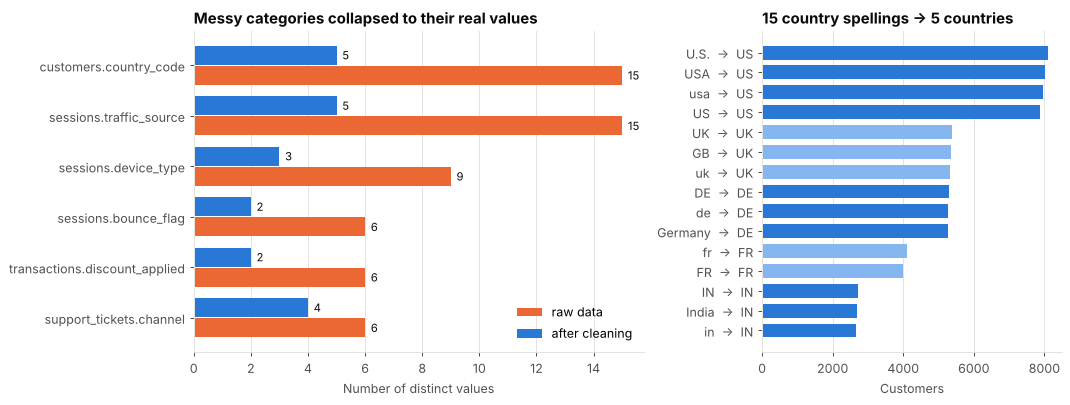

In [4]:
cat_checks = [
    ("customers.country_code", cust_raw["country_code"], cust_cl["country_code"]),
    ("sessions.traffic_source", sess_raw["traffic_source"], sess_cl["traffic_source"]),
    ("sessions.device_type", sess_raw["device_type"], sess_cl["device_type"]),
    ("sessions.bounce_flag", sess_raw["bounce_flag"], sess_cl["bounce_flag"]),
    ("transactions.discount_applied", txn_raw["discount_applied"], txn_cl["discount_applied"]),
    ("support_tickets.channel", tick_raw["channel"], tick_cl["channel"]),
]
cat_tbl = pd.DataFrame([(n, r.nunique(), c.nunique()) for n, r, c in cat_checks],
                       columns=["column", "values before", "values after"])
display(cat_tbl)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.6), gridspec_kw={"width_ratios": [1.5, 1]})
ax = axes[0]
y = np.arange(len(cat_tbl))
ax.barh(y + 0.2, cat_tbl["values before"], height=0.38, color=ORANGE, label="raw data")
ax.barh(y - 0.2, cat_tbl["values after"], height=0.38, color=BLUE, label="after cleaning")
for i, (b, a) in enumerate(zip(cat_tbl["values before"], cat_tbl["values after"])):
    ax.text(b + 0.2, i + 0.2, str(b), va="center", color=INK, fontsize=9)
    ax.text(a + 0.2, i - 0.2, str(a), va="center", color=INK, fontsize=9)
ax.set_yticks(y, cat_tbl["column"]); ax.invert_yaxis()
ax.set_xlabel("Number of distinct values"); ax.legend(loc="lower right"); ax.grid(axis="x"); ax.grid(axis="y", visible=False)
ax.set_title("Messy categories collapsed to their real values")
ax = axes[1]
cc = cust_raw["country_code"].value_counts()
mapping = {"U.S.": "US", "USA": "US", "usa": "US", "US": "US", "UK": "UK", "GB": "UK", "uk": "UK", "DE": "DE", "de": "DE",
           "Germany": "DE", "FR": "FR", "fr": "FR", "IN": "IN", "India": "IN", "in": "IN"}
order = sorted(cc.index, key=lambda s: (["US", "UK", "DE", "FR", "IN"].index(mapping[s]), -cc[s]))
ax.barh(range(len(order)), cc[order], color=[BLUE if mapping[s] in ("US", "DE", "IN") else LIGHTBLUE for s in order], height=0.7)
ax.grid(axis="x"); ax.grid(axis="y", visible=False)
ax.set_yticks(range(len(order)), [f"{s}  →  {mapping[s]}" for s in order]); ax.invert_yaxis()
ax.set_xlabel("Customers"); ax.set_title("15 country spellings → 5 countries")
fig.tight_layout(); save(fig, "c01_messy_categories")

**Finding:** Six columns stored the same value in many ways: "U.S.", "USA", "usa" and "US" are all one country, and `bounce_flag` had 6 encodings of yes/no. Without cleaning, a model would treat "USA" and "US" as different countries and split one signal into four weak ones.

**Decision:** Mapped each column to its real values in KNIME (Rule Engine, or String Manipulation + lowercase). Verified above: 15 → 5 countries, 15 → 5 traffic sources, 9 → 3 devices, 6 → 2 bounce values, 6 → 2 discount values, 6 → 4 ticket channels.

### 1.2 Impossible, missing and duplicated values

In [5]:
age_num = pd.to_numeric(cust_raw["age"], errors="coerce")
review = pd.to_numeric(cust_raw["avg_review_score"], errors="coerce")
order_val = pd.to_numeric(txn_raw["order_value"].str.replace(r"[$,]", "", regex=True), errors="coerce")
dur_raw = pd.to_numeric(sess_raw["session_duration"], errors="coerce")
delivered = pd.to_datetime(deliv_raw["delivered_date"], errors="coerce")
dedup = ~txn_raw.duplicated()
high_val = txn_raw["high_value_flag"].isin(["1", "True", "TRUE", "Yes"])

canon = {"country": ["US", "UK", "DE", "FR", "IN"], "traffic": ["organic", "ads", "email", "social", "direct"]}
log = pd.DataFrame([
    ("customers", "country_code spelled 15 ways for 5 countries", (~cust_raw.country_code.isin(canon["country"])).sum(), "Mapped to 5 country codes", "Rule Engine"),
    ("customers", "age = 'unknown'", (cust_raw.age == "unknown").sum(), "Flag age_missing, then median impute", "Rule Engine + Missing Value"),
    ("customers", "age = 18 spike (likely a default value)", (age_num == 18).sum(), "Flag age_is_18", "Rule Engine"),
    ("customers", "email_open_rate blank", (cust_raw.email_open_rate == "").sum(), "Flag + median impute", "Rule Engine + Missing Value"),
    ("customers", "avg_review_score above 5 (scale is 1–5)", (review > 5).sum(), "Flag + cap at 5.0", "Rule Engine"),
    ("customers", "credit_limit stored as text ('$1,569')", cust_raw.credit_limit.str.contains(r"\$").sum(), "Strip $ and commas, to number", "String Manipulation + String to Number"),
    ("customers", "5 noise columns with no meaning (columns, not rows)", 5, "Removed", "Column Filter"),
    ("sessions", "bounce_flag not stored as 0/1 (TRUE, Yes, No…)", (~sess_raw.bounce_flag.isin(["0", "1"])).sum(), "Mapped to 0/1", "Rule Engine"),
    ("sessions", "traffic_source / device_type in mixed case", (~sess_raw.traffic_source.isin(canon["traffic"])).sum(), "Lowercase + trim", "String Manipulation"),
    ("sessions", "pages_viewed blank", (sess_raw.pages_viewed == "").sum(), "Flag pages_missing + median impute", "Rule Engine + Missing Value"),
    ("sessions", "session_duration over 4 hours", (dur_raw > 14400).sum(), "Flag long_session + cap at 14,400 s", "Rule Engine"),
    ("transactions", "exact duplicate orders", txn_raw.duplicated().sum(), "Removed", "Duplicate Row Filter"),
    ("transactions", "order_value = $0.00", (order_val[dedup] == 0).sum(), "Rebuilt from item prices", "GroupBy + Joiner + Rule Engine"),
    ("transactions", "$0 orders still flagged high-value", (high_val & (order_val == 0))[dedup].sum(), "Recomputed high_value_flag (> $250)", "Rule Engine"),
    ("transactions", "discount_applied not stored as 0/1", (~txn_raw.discount_applied.isin(["0", "1"])).sum(), "Mapped to 0/1", "Rule Engine"),
    ("deliveries", "delivered_date after the 2024-09-30 cutoff", (delivered > CUTOFF).sum(), "Blanked; status set to 'In Transit' (leakage)", "Rule Engine"),
    ("support_tickets", "channel spelled 'CHAT' or 'email'", tick_raw.channel.isin(["CHAT", "email"]).sum(), "Mapped to 4 channels", "Rule Engine"),
    ("support_tickets", "csat_score blank", (tick_raw.csat_score == "").sum(), "Flag csat_missing, not imputed", "Rule Engine"),
], columns=["table", "issue", "rows affected", "fix", "KNIME node"])
display(log)

checks = pd.DataFrame([
    ("countries after cleaning", cust_cl.country_code.nunique(), 5),
    ("'unknown' ages left", int((cust_cl.age.astype(str) == "unknown").sum()), 0),
    ("max avg_review_score", cust_cl.avg_review_score.max(), 5.0),
    ("max session_duration (s)", sess_cl.session_duration.max(), 14400.0),
    ("blank pages_viewed", int(sess_cl.pages_viewed.isna().sum()), 0),
    ("transaction rows", len(txn_cl), 301243),
    ("$0 orders left", int((txn_cl.order_value == 0).sum()), 0),
    ("delivered dates after cutoff", int((pd.to_datetime(deliv_cl.delivered_date) > CUTOFF).sum()), 0),
], columns=["check on cleaned data", "result", "expected"])
checks["pass"] = np.where(np.isclose(checks["result"].astype(float), checks["expected"].astype(float)), "✓", "✗")
display(checks)

,table,issue,rows affected,fix,KNIME node
0,customers,country_code spelled 15 ways for 5 countries,54721,Mapped to 5 country codes,Rule Engine
1,customers,age = 'unknown',4119,"Flag age_missing, then median impute",Rule Engine + Missing Value
2,customers,age = 18 spike (likely a default value),5125,Flag age_is_18,Rule Engine
3,customers,email_open_rate blank,14559,Flag + median impute,Rule Engine + Missing Value
4,customers,avg_review_score above 5 (scale is 1–5),313,Flag + cap at 5.0,Rule Engine
5,customers,"credit_limit stored as text ('$1,569')",80000,"Strip $ and commas, to number",String Manipulation + String to Number
6,customers,"5 noise columns with no meaning (columns, not rows)",5,Removed,Column Filter
7,sessions,"bounce_flag not stored as 0/1 (TRUE, Yes, No…)",961311,Mapped to 0/1,Rule Engine
8,sessions,traffic_source / device_type in mixed case,962512,Lowercase + trim,String Manipulation
9,sessions,pages_viewed blank,71958,Flag pages_missing + median impute,Rule Engine + Missing Value


,check on cleaned data,result,expected,pass
0,countries after cleaning,5.0,5.0,✓
1,'unknown' ages left,0.0,0.0,✓
2,max avg_review_score,5.0,5.0,✓
3,max session_duration (s),14400.0,14400.0,✓
4,blank pages_viewed,0.0,0.0,✓
5,transaction rows,301243.0,301243.0,✓
6,$0 orders left,0.0,0.0,✓
7,delivered dates after cutoff,0.0,0.0,✓


**Finding:** Every issue in the cleaning log is fixed in the cleaned files: all 8 checks pass. The most important one is the **510 deliveries dated after the cutoff**. Section 1.3 shows why.

**Decision:** Keep a "flag, then fix" pattern: whenever a value was wrong or missing, the workflow adds a 0/1 flag (`age_missing`, `age_is_18`, `review_out_of_range`, `email_open_rate_missing`) before fixing it, so the model can still learn from the fact that something was wrong.

### 1.3 Leakage catch: deliveries from the future

In [6]:
future = deliv_raw.loc[delivered > CUTOFF]
print("Deliveries with delivered_date after 2024-09-30:", len(future))
print("Months they fall in:", delivered[delivered > CUTOFF].dt.to_period("M").value_counts().to_dict())
print("Raw delivery_status of those rows:", future["delivery_status"].value_counts().to_dict())

Deliveries with delivered_date after 2024-09-30: 510
Months they fall in: {Period('2024-10', 'M'): 510}
Raw delivery_status of those rows: {'Delivered': 453, 'Delivered Late': 44, 'Returned': 13}


**Finding:** All 510 future delivery dates fall in **October 2024**, the exact month we're predicting. A model that saw "delivered in October" would be learning from the future and would look better in testing than it ever could in real use.

**Decision:** The cleaning workflow blanks these dates and resets their status to "In Transit" (the status known on 2024-09-30). The feature workflow only uses `delivery_status_at_cutoff`, never the raw `delivery_status`.

### 1.4 Session duration before and after the 4-hour cap

Sessions over 4 h: 1,484 of 1,442,550 (0.10%); raw max = 25.0 h; 99th percentile = 28 min


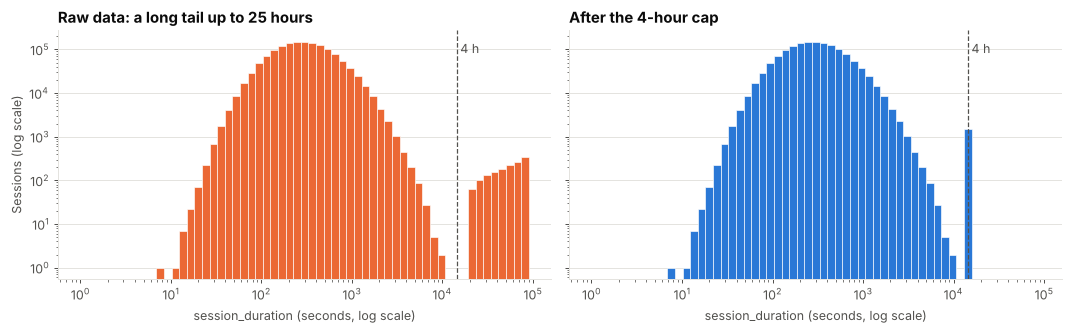

In [7]:
edges = np.logspace(0, np.log10(dur_raw.max() + 1), 60)
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8), sharey=True)
for ax, s, title, col in [(axes[0], dur_raw, "Raw data: a long tail up to 25 hours", ORANGE),
                          (axes[1], sess_cl["session_duration"], "After the 4-hour cap", BLUE)]:
    ax.hist(s.dropna().clip(lower=1), bins=edges, color=col, edgecolor="white", linewidth=0.5)
    ax.set_xscale("log"); ax.set_yscale("log")
    ax.axvline(14400, color=INK2, ls="--", lw=1); ax.text(14400, ax.get_ylim()[1] * 0.3, " 4 h", color=INK2)
    ax.set_title(title); ax.set_xlabel("session_duration (seconds, log scale)")
axes[0].set_ylabel("Sessions (log scale)")
fig.tight_layout(); save(fig, "c02_session_duration_cap")
print(f"Sessions over 4 h: {(dur_raw > 14400).sum():,} of {len(dur_raw):,} ({(dur_raw > 14400).mean():.2%}); "
      f"raw max = {dur_raw.max() / 3600:.1f} h; 99th percentile = {dur_raw.quantile(.99) / 60:.0f} min")

**Finding:** 99% of sessions last under 28 minutes, but 1,484 sessions (0.1%) last over 4 hours, the longest about 25 hours. These are almost certainly tabs left open, not real browsing. Left in, one 25-hour session would dominate a customer's average session time.

**Decision:** Cap at 4 hours (14,400 s) and keep a `long_session` flag. The cap removes the impossible part of the tail without deleting any customers.

### 1.5 Policy check: past offers that broke the tier rules (evidence for wish-list W4)

,offer_code,customer_tier,contacts
0,OFF-V15,Bronze,67
1,OFF-V20,Bronze,67
2,OFF-V20,Gold,25
3,OFF-V20,Silver,36


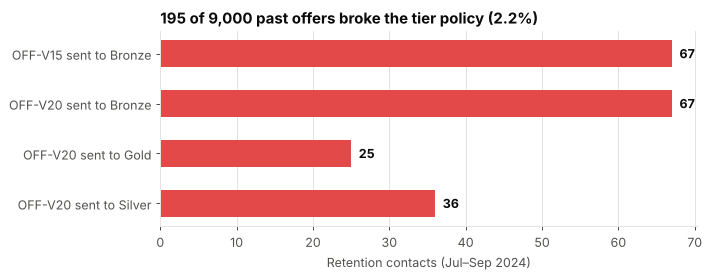

In [8]:
rch = clean_csv("retention_contact_history")
viol = rch[rch["policy_violation"] == 1].groupby(["offer_code", "customer_tier"]).size().rename("contacts").reset_index()
display(viol)
fig, ax = plt.subplots(figsize=(8, 3.2))
labels = [f"{o} sent to {t}" for o, t in zip(viol.offer_code, viol.customer_tier)]
ax.barh(labels, viol["contacts"], color=RED, height=0.55)
for i, v in enumerate(viol["contacts"]):
    ax.text(v + 1, i, str(v), va="center", color=INK, fontweight="bold")
ax.invert_yaxis(); ax.set_xlabel("Retention contacts (Jul–Sep 2024)"); ax.grid(axis="x"); ax.grid(axis="y", visible=False)
ax.set_title(f"{viol.contacts.sum()} of {len(rch):,} past offers broke the tier policy ({viol.contacts.sum() / len(rch):.1%})")
fig.tight_layout(); save(fig, "c03_policy_violations")

**Finding:** **195 of 9,000 past offers (2.2%) broke `retention_offer_policy.md`.** OFF-V20 (Platinum only) went to 128 Bronze, Silver and Gold customers, and OFF-V15 went to 67 Bronze customers. This matches the CRM executive's complaint in the brief ("a 20% voucher to Bronze by mistake"). Our project plan estimated about 134, but that only counted Bronze customers; the policy also excludes Silver and Gold from OFF-V20.

**Decision:** This isn't a model feature. It's evidence for **W4 (policy checks at decision time)**: the agent must check tier eligibility before any offer goes out.

## 2. Target balance

Buy rate = 14.6%. A model that always predicts 'no' scores 85.4% accuracy.
Class weight for the positive class (negatives ÷ positives) = 5.86


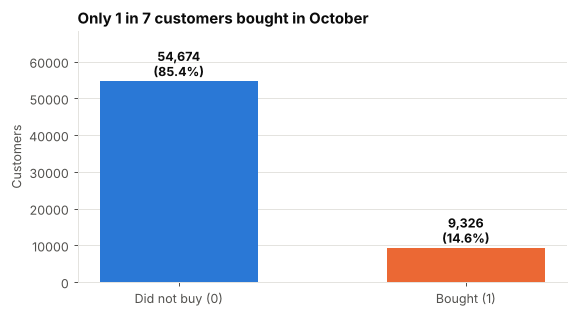

In [9]:
counts = train["target"].value_counts().sort_index()
fig, ax = plt.subplots(figsize=(6.5, 3.6))
bars = ax.bar(["Did not buy (0)", "Bought (1)"], counts.values, color=[NONBUYER, BUYER], width=0.55)
for b, v in zip(bars, counts.values):
    ax.text(b.get_x() + b.get_width() / 2, v + 600, f"{v:,}\n({v / counts.sum():.1%})", ha="center", va="bottom", color=INK, fontweight="bold")
ax.set_ylim(0, counts.max() * 1.25); ax.set_ylabel("Customers")
ax.set_title("Only 1 in 7 customers bought in October")
fig.tight_layout(); save(fig, "c04_target_balance")
pos_weight = counts[0] / counts[1]
print(f"Buy rate = {OVERALL:.1%}. A model that always predicts 'no' scores {1 - OVERALL:.1%} accuracy.")
print(f"Class weight for the positive class (negatives ÷ positives) = {pos_weight:.2f}")

**Finding:** 14.6% of customers bought (9,326 of 64,000) and 85.4% did not. The classes are **imbalanced**: a useless model that always says "no" already scores 85.4% accuracy, so accuracy can't tell a good model from a bad one.

**Decisions for the MLP:**
1. **Main metrics: PR-AUC and F1 for the buyer class**, with ROC-AUC, precision and recall reported alongside. The baseline to beat is the recency rule (Section 3.1), not "85% accuracy".
2. **Class weighting:** weight buyers by about **5.9** (`pos_weight = 54,674 / 9,326`) in the loss, so the network doesn't learn to ignore them.
3. **Stratified train/validation split** on `target`, so both parts keep the 14.6% rate.
4. **Tune the decision threshold** on the validation set (for F1 or for the CRM team's budget) instead of using 0.5.

## 3. Purchase rate by feature: which signals matter?
Method: group customers by a feature and take the mean of `target`. That mean is the **purchase rate** of the group. The dashed line is the overall rate (14.6%).
### 3.1 Recency (the CRM team's current rule)

,rate,n
recency_bucket,,
0–30 days,40.8%,"9,580"
31–90,28.4%,"8,653"
91–365,13.7%,"14,164"
365+,2.6%,"6,963"
never ordered,3.4%,"24,640"


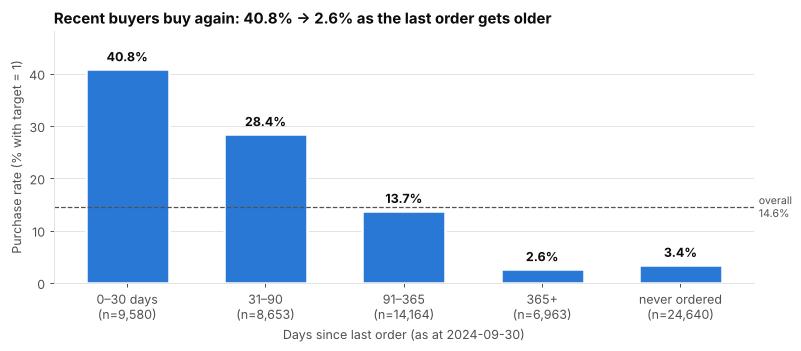

In [10]:
def recency_bucket(days, never):
    if never == 1: return "never ordered"
    if days <= 30: return "0–30 days"
    if days <= 90: return "31–90"
    if days <= 365: return "91–365"
    return "365+"

train["recency_bucket"] = [recency_bucket(d, n) for d, n in zip(train.days_since_last_order, train.never_ordered)]
rec = purchase_rate(train, "recency_bucket")
rec_order = ["0–30 days", "31–90", "91–365", "365+", "never ordered"]
display(rec.loc[rec_order].style.format({"rate": "{:.1%}", "n": "{:,}"}))
fig, ax = plt.subplots(figsize=(9, 4))
rate_bars(ax, rec, "Recent buyers buy again: 40.8% → 2.6% as the last order gets older",
          "Days since last order (as at 2024-09-30)", OVERALL, rec_order)
fig.tight_layout(); save(fig, "c05_recency")

**Finding:** The purchase rate falls steadily with recency: **40.8% (0–30 days) → 28.4% → 13.7% → 2.6% (365+ days)**. Customers who never ordered buy at only 3.4%. This is the strongest single signal, and it's exactly what the CRM team uses today.

**Decision:** `days_since_last_order` stays in the model, but **recency alone is the baseline the MLP must beat.** The next cell measures that baseline, so PR1 has a concrete number to compare against.

In [11]:
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
baselines = {
    "Always 'no' (no model)": None,
    "Recency only (today's CRM rule)": ["days_since_last_order", "never_ordered"],
    "Simple 5-feature logistic regression": ["days_since_last_order", "never_ordered", "sessions_90d", "orders_365d", "tier_rank"],
}
rows = []
for name, cols in baselines.items():
    if cols is None:
        rows.append((name, OVERALL, 0.5)); continue
    model = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))
    pr = cross_val_score(model, train[cols], train.target, cv=cv, scoring="average_precision").mean()
    roc = cross_val_score(model, train[cols], train.target, cv=cv, scoring="roc_auc").mean()
    rows.append((name, pr, roc))
bench = pd.DataFrame(rows, columns=["benchmark", "PR-AUC", "ROC-AUC"]).round(3)
display(bench)

,benchmark,PR-AUC,ROC-AUC
0,Always 'no' (no model),0.146,0.500
1,Recency only (today's CRM rule),0.373,0.802
2,Simple 5-feature logistic regression,0.538,0.850


**Finding:** Guessing gives a PR-AUC of 0.146 (the buy rate). **Recency alone reaches 0.373**, and a simple logistic regression on five obvious features reaches **0.538**.

**Decision:** This is a quick *signal check* (5-fold cross-validation on all 64,000 labelled customers), not the official comparison. It shows recency alone gets about a third of the way, and a few more behaviour features add a lot. The **official targets** for the MLP are the team baselines in `results/baseline_results.csv`, measured on the shared 70/15/15 split (`01_baselines.ipynb`): recency rule **val PR-AUC 0.366**, logistic regression **0.562**, LightGBM **0.563**. The MLP must beat the recency rule to be better than the CRM team's current method, and should match or beat LightGBM to justify a neural network.

### 3.2 Browsing activity: sessions in the last 30 days

,rate,n
sessions_30d_bucket,,
0,4.3%,"37,067"
1–2,20.1%,"18,376"
3–5,41.1%,"6,850"
6+,71.8%,"1,707"


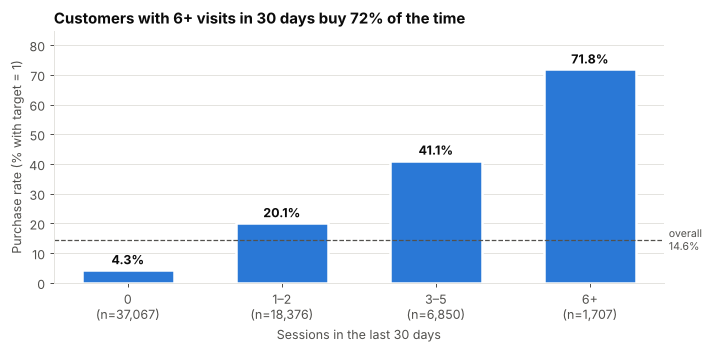

sessions_30d_bucket,0,1–2,3–5,6+
recency_bucket,,,,
0–30 days,nan%,24.2%,44.3%,71.9%
31–90,17.7%,30.0%,45.8%,75.6%
91–365,7.9%,19.3%,30.0%,57.7%
365+,1.2%,10.6%,17.6%,50.0%
never ordered,1.7%,9.4%,23.9%,66.7%


In [12]:
train["sessions_30d_bucket"] = pd.cut(train["sessions_30d"], [-1, 0, 2, 5, np.inf], labels=["0", "1–2", "3–5", "6+"])
s30 = purchase_rate(train, "sessions_30d_bucket")
display(s30.style.format({"rate": "{:.1%}", "n": "{:,}"}))
fig, ax = plt.subplots(figsize=(8, 4))
rate_bars(ax, s30, "Customers with 6+ visits in 30 days buy 72% of the time", "Sessions in the last 30 days", OVERALL)
fig.tight_layout(); save(fig, "c06_sessions_30d")

# within each recency bucket, does browsing still add information?
inter = train.pivot_table(index="recency_bucket", columns="sessions_30d_bucket", values="target", aggfunc="mean", observed=True).loc[rec_order]
display(inter.style.format("{:.1%}").background_gradient(cmap="Blues", axis=None))

**Finding:** Purchase rate climbs from **4.3% (no visits) to 20.1%, 41.1% and 71.8% (6+ visits)**. The table shows this isn't just recency in disguise: **inside every recency bucket**, customers who browse more buy more. Even "never ordered" customers with recent visits buy far above 3.4%.

**Decision:** Session features (`sessions_30d`, `sessions_90d`, `days_since_last_session`, `cart_adds_30d`) carry information that recency misses, which is why the MLP combines all sources instead of using recency alone. These count features are skewed, so they get `log1p` + scaling (Section 8).

### 3.3 Loyalty tier, and other customer flags

,rate,n,share
customer_tier,,,
Bronze,5.4%,"40,778",64%
Silver,19.3%,"10,833",17%
Gold,30.9%,"6,910",11%
Platinum,52.7%,"5,479",9%


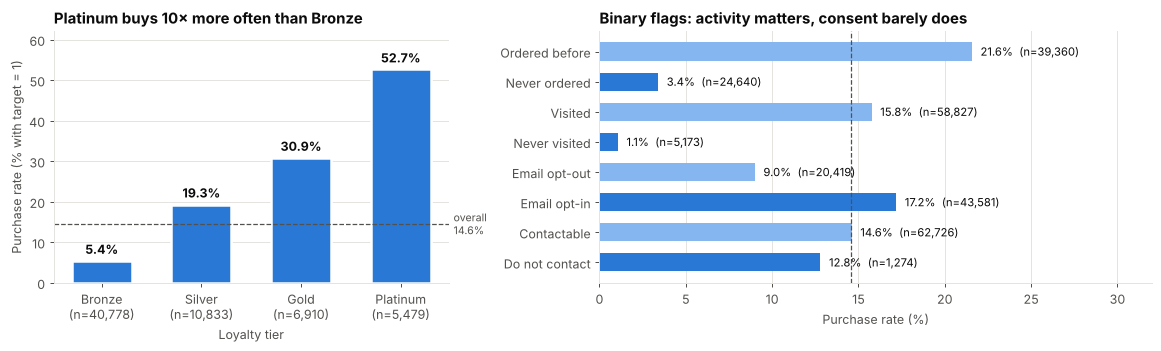

In [13]:
tier = purchase_rate(train, "customer_tier").loc[["Bronze", "Silver", "Gold", "Platinum"]]
tier["share"] = tier["n"] / tier["n"].sum()
display(tier.style.format({"rate": "{:.1%}", "n": "{:,}", "share": "{:.0%}"}))

flags = {
    "never_ordered": ("Ordered before", "Never ordered"),
    "never_visited": ("Visited", "Never visited"),
    "email_opt_in": ("Email opt-out", "Email opt-in"),
    "do_not_contact": ("Contactable", "Do not contact"),
}
fig, axes = plt.subplots(1, 2, figsize=(13, 4), gridspec_kw={"width_ratios": [1, 1.4]})
rate_bars(axes[0], tier, "Platinum buys 10× more often than Bronze", "Loyalty tier", OVERALL)
rows = []
for col, (l0, l1) in flags.items():
    r = purchase_rate(train, col)
    rows += [(f"{l0}", r.loc[0, "rate"], r.loc[0, "n"], col), (f"{l1}", r.loc[1, "rate"], r.loc[1, "n"], col)]
ft = pd.DataFrame(rows, columns=["group", "rate", "n", "feature"])
ypos = np.arange(len(ft))[::-1]
axes[1].barh(ypos, ft["rate"] * 100, color=[LIGHTBLUE if i % 2 == 0 else BLUE for i in range(len(ft))], height=0.6)
axes[1].grid(axis="x"); axes[1].grid(axis="y", visible=False)
for y, r, n in zip(ypos, ft["rate"], ft["n"]):
    axes[1].text(r * 100 + 0.5, y, f"{r:.1%}  (n={n:,})", va="center", color=INK, fontsize=9)
axes[1].set_yticks(ypos, ft["group"]); axes[1].axvline(OVERALL * 100, color=INK2, ls="--", lw=1)
axes[1].set_xlabel("Purchase rate (%)"); axes[1].set_xlim(0, 32); axes[1].set_title("Binary flags: activity matters, consent barely does")
fig.tight_layout(); save(fig, "c07_tier_and_flags")

**Finding:** Tier is a strong ordered signal: **Bronze 5.4% → Silver 19.3% → Gold 30.9% → Platinum 52.7%**. But **Bronze is 64% of customers**, so most of the base rarely buys. Customers who never ordered (3.4%) or never visited buy far less than everyone else. Email opt-in customers buy almost twice as often as opt-outs (17.2% vs 9.0%). Do-not-contact customers buy at nearly the normal rate (12.8%).

**Decisions:** Use `tier_rank` (0–3) rather than one-hot tiers, because the order carries meaning. Keep the `never_*` flags: they tell the MLP *why* a count is zero (Section 4.2). `do_not_contact` stays out of the **targeting** decision (the agent must not contact them), but it can stay in the **prediction** model, because predicting who buys is different from deciding who to message.

### 3.4 Which features separate buyers from non-buyers the most?
A quick ranking for all numeric features: the standardised mean difference (SMD), i.e. how many standard deviations the buyers' average is away from the non-buyers' average. Above 0.5 is a strong separation.

Features with |SMD| < 0.05 (almost no difference): ['credit_limit', 'age_missing', 'review_out_of_range', 'average_income', 'urban_ratio', 'internet_penetration', 'bounce_rate', 'has_open_high_priority', 'avg_csat', 'sms_opt_in', 'do_not_contact']


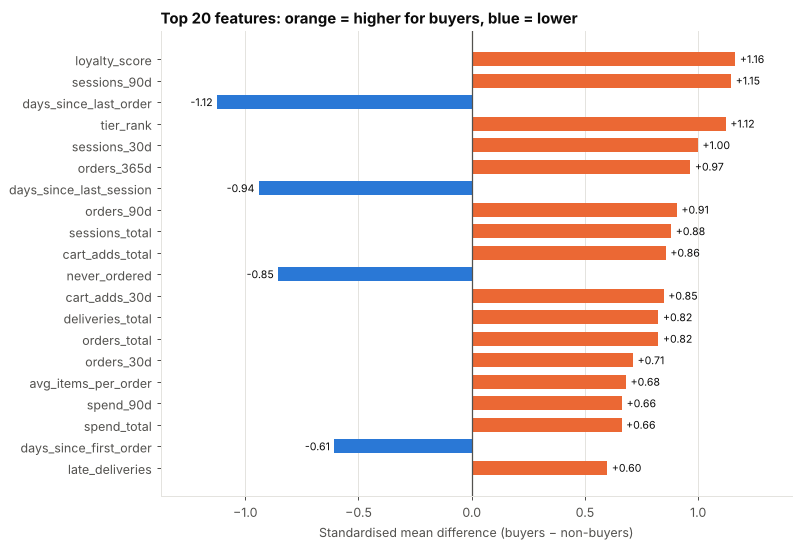

In [14]:
num_cols = [c for c in train.select_dtypes("number").columns if c not in ("customer_id", "target")]
g = train.groupby("target")[num_cols]
smd = ((g.mean().loc[1] - g.mean().loc[0]) / np.sqrt((g.var().loc[1] + g.var().loc[0]) / 2)).dropna()
top = smd.reindex(smd.abs().sort_values(ascending=False).index).head(20)
fig, ax = plt.subplots(figsize=(9, 6.2))
ax.barh(top.index[::-1], top.values[::-1], color=[BUYER if v > 0 else NONBUYER for v in top.values[::-1]], height=0.65)
ax.axvline(0, color=INK2, lw=1); ax.grid(axis="x"); ax.grid(axis="y", visible=False)
for i, v in enumerate(top.values[::-1]):
    ax.text(v + (0.02 if v > 0 else -0.02), i, f"{v:+.2f}", va="center", ha="left" if v > 0 else "right", color=INK, fontsize=8.5)
ax.set_xlabel("Standardised mean difference (buyers − non-buyers)")
ax.set_title("Top 20 features: orange = higher for buyers, blue = lower")
ax.set_xlim(top.min() - 0.25, top.max() + 0.25)
fig.tight_layout(); save(fig, "c08_feature_separation")
print("Features with |SMD| < 0.05 (almost no difference):", list(smd[smd.abs() < 0.05].index))

**Finding:** The strongest separators are **`loyalty_score`** (+1.16), **recent browsing** (`sessions_90d`, `sessions_30d`), **tier** (+1.12), **recency** (`days_since_last_order`, −1.12) and recent orders. Profile and region features (credit limit, income, urban ratio, internet penetration) barely differ between buyers and non-buyers (|SMD| < 0.05).

**Leakage check on `loyalty_score`:** a black-box score at the top of the list could be leaking the future, so I checked it (next cell). It predicts about as well as recency alone (ROC-AUC 0.80, not suspiciously high), it correlates 0.52–0.59 with recency, orders and sessions, and the data README says it's measured "as at the cutoff". So it's a legitimate summary of past engagement, not leakage. It still separates buyers *within* every tier, so it adds information.

**Decision:** No single feature explains everything, and the signals come from different tables (orders, sessions, tier, support), which suits an MLP that can combine them. Weak features stay in for now, because the network can learn interactions. If validation shows overfitting, they're the first candidates to drop. `loyalty_score` is kept, but because it's an opaque internal index, the agent's explanations should cite the behaviour behind it (recent visits and orders) rather than "a high loyalty score".

In [15]:
from sklearn.metrics import roc_auc_score
print("loyalty_score ROC-AUC on its own:", round(roc_auc_score(train.target, train.loyalty_score), 3),
      "| recency on its own:", round(roc_auc_score(train.target, -train.days_since_last_order), 3))
print("Correlation of loyalty_score with:", train[["tier_rank", "sessions_90d", "orders_365d", "days_since_last_order"]].corrwith(train.loyalty_score).round(2).to_dict())
loy = train.assign(loyalty_quartile=pd.qcut(train.loyalty_score, 4, labels=["Q1 (low)", "Q2", "Q3", "Q4 (high)"]))
display(loy.pivot_table(index="customer_tier", columns="loyalty_quartile", values="target", aggfunc="mean", observed=True)
        .loc[["Bronze", "Silver", "Gold", "Platinum"]].style.format("{:.1%}"))

loyalty_score ROC-AUC on its own: 0.795 | recency on its own: 0.798
Correlation of loyalty_score with: {'tier_rank': 0.56, 'sessions_90d': 0.58, 'orders_365d': 0.59, 'days_since_last_order': -0.52}


loyalty_quartile,Q1 (low),Q2,Q3,Q4 (high)
customer_tier,,,,
Bronze,1.6%,4.4%,8.6%,13.9%
Silver,6.7%,11.7%,19.0%,28.8%
Gold,9.7%,16.2%,25.0%,39.9%
Platinum,12.3%,20.0%,31.3%,60.4%


## 4. Distributions, outliers and special values
### 4.1 Skewed money and count columns

,skew (raw),skew after log1p,median,99th pct,max
spend_total,7.31,-0.11,90.46,5511.33,34828.21
avg_order_value,3.21,-0.28,50.99,508.16,2275.83
orders_total,5.04,0.82,1.00,37.00,184.00
sessions_total,3.78,-0.07,9.00,122.00,528.00
avg_session_duration,19.41,-2.79,336.89,920.07,14400.00
bounce_rate,16.01,12.54,0.00,0.12,1.00


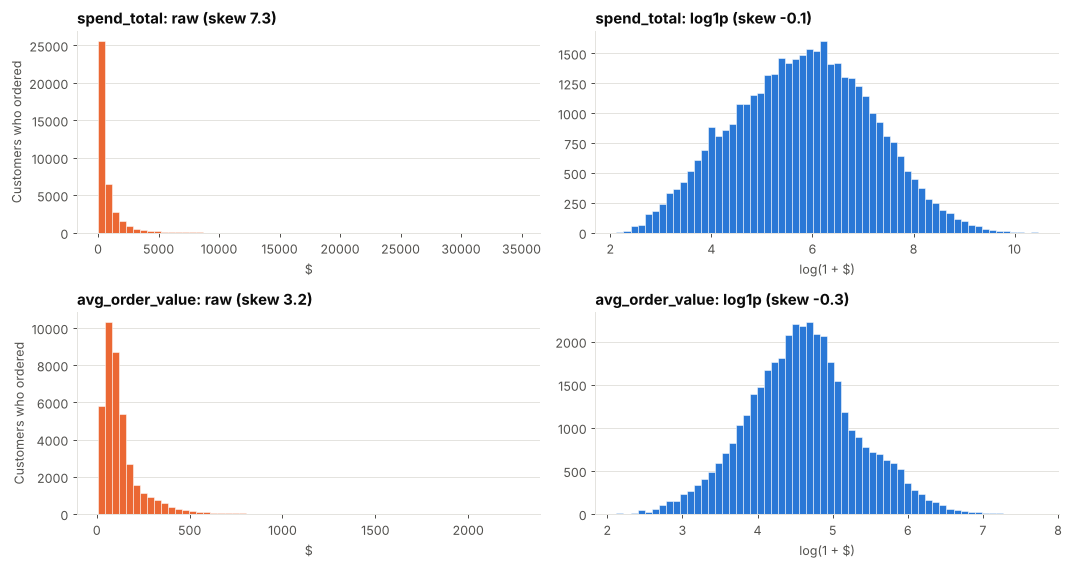

In [16]:
skew_cols = ["spend_total", "avg_order_value", "orders_total", "sessions_total", "avg_session_duration", "bounce_rate"]
skew_tbl = pd.DataFrame({"skew (raw)": train[skew_cols].skew(), "skew after log1p": np.log1p(train[skew_cols]).skew(),
                         "median": train[skew_cols].median(), "99th pct": train[skew_cols].quantile(.99), "max": train[skew_cols].max()}).round(2)
display(skew_tbl)
fig, axes = plt.subplots(2, 2, figsize=(12, 6.4))
for row, col in enumerate(["spend_total", "avg_order_value"]):
    pos = train.loc[train[col] > 0, col]
    axes[row, 0].hist(pos, bins=60, color=ORANGE, edgecolor="white", linewidth=0.4)
    axes[row, 0].set_title(f"{col}: raw (skew {train[col].skew():.1f})"); axes[row, 0].set_xlabel("$")
    axes[row, 1].hist(np.log1p(pos), bins=60, color=BLUE, edgecolor="white", linewidth=0.4)
    axes[row, 1].set_title(f"{col}: log1p (skew {np.log1p(train[col]).skew():.1f})"); axes[row, 1].set_xlabel("log(1 + $)")
for ax in axes[:, 0]: ax.set_ylabel("Customers who ordered")
fig.tight_layout(); save(fig, "c09_skew_log_transform")

**Finding:** Money and count columns are **heavily right-skewed**: `spend_total` has skew 7.3, a median of \$90 and a maximum of \$34,828. On the raw scale, a few big spenders squash everyone else into one bar. After `log1p`, the shape becomes close to bell-shaped.

**Decision:** Apply `log1p` to skewed money/count columns, then standardise. Neural networks train poorly when inputs are on wildly different scales: large raw values dominate the first-layer weights and slow down gradient descent. The transform is fitted on the training split only.

### 4.2 The "1100" sentinel in `days_since_*` columns

Correlation of days_since_last_order with target, all rows: -0.331
…only customers who ordered: -0.29


,rows = 1100,% of customers,max real value
days_since_last_order,24640,38.5,1003.0
days_since_first_order,24640,38.5,1003.0
days_since_last_session,5173,8.1,1003.0
days_since_last_ticket,49018,76.6,999.0
days_since_last_contact,56818,88.8,91.0


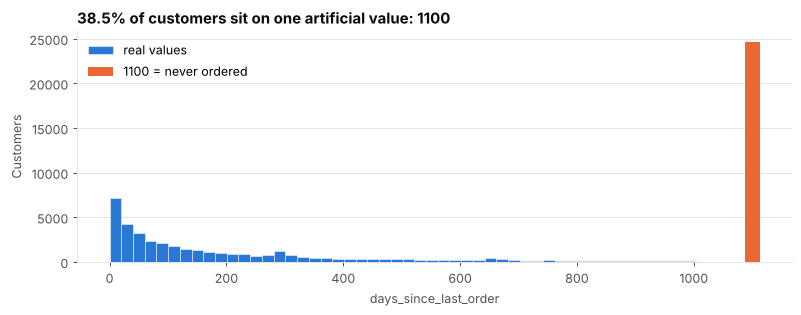

In [17]:
day_cols = ["days_since_last_order", "days_since_first_order", "days_since_last_session", "days_since_last_ticket", "days_since_last_contact"]
sent = pd.DataFrame({"rows = 1100": (train[day_cols] == SENTINEL).sum(), "% of customers": (train[day_cols] == SENTINEL).mean().mul(100).round(1),
                     "max real value": train[day_cols].where(train[day_cols] < SENTINEL).max()})
display(sent)
fig, ax = plt.subplots(figsize=(9, 3.6))
ax.hist(train.loc[train.days_since_last_order < SENTINEL, "days_since_last_order"], bins=50, color=BLUE, edgecolor="white", linewidth=0.4, label="real values")
ax.bar(SENTINEL, (train.days_since_last_order == SENTINEL).sum(), width=25, color=ORANGE, label="1100 = never ordered")
ax.set_xlabel("days_since_last_order"); ax.set_ylabel("Customers"); ax.legend()
ax.set_title("38.5% of customers sit on one artificial value: 1100")
fig.tight_layout(); save(fig, "c10_sentinel_1100")
print("Correlation of days_since_last_order with target, all rows:", round(train.days_since_last_order.corr(train.target), 3))
print("…only customers who ordered:", round(train.loc[train.never_ordered == 0, "days_since_last_order"].corr(train.loc[train.never_ordered == 0, "target"]), 3))

**Finding:** The feature workflow fills "never happened" with **1100 days** (longer than the 1,003 days of history). That's 38.5% of `days_since_last_order`, 76.6% of `days_since_last_ticket` and 88.8% of `days_since_last_contact`. Means, standard deviations and correlations computed on these columns are distorted by the spike.

**Decision:** Keep 1100 (it correctly means "a very long time"), but always pair it with the `never_*` flags so the MLP can tell "never" from "a long time ago". Scaling uses a robust approach (Section 8), so the spike doesn't squash the real values.

### 4.3 Age: two spikes created by the data, not by people

Customers with age_missing = 1: 3342 | their filled-in age: [38]


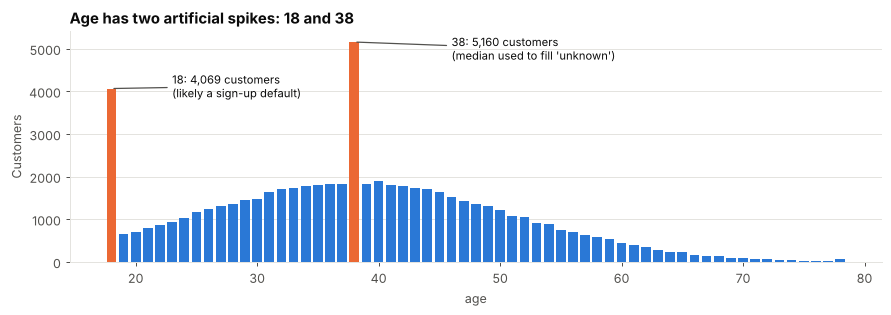

,rate,n
age_is_18,,
0,14.3%,"59,931"
1,18.9%,"4,069"


In [18]:
fig, ax = plt.subplots(figsize=(10, 3.6))
vc = train["age"].value_counts().sort_index()
ax.bar(vc.index, vc.values, color=[ORANGE if a in (18, 38) else BLUE for a in vc.index], width=0.8)
ax.annotate(f"18: {vc[18]:,} customers\n(likely a sign-up default)", xy=(18, vc[18]), xytext=(23, vc[18] * 0.95), color=INK, fontsize=9, arrowprops=dict(arrowstyle="-", color=INK2))
ax.annotate(f"38: {vc[38]:,} customers\n(median used to fill 'unknown')", xy=(38, vc[38]), xytext=(46, vc[38] * 0.92), color=INK, fontsize=9, arrowprops=dict(arrowstyle="-", color=INK2))
ax.set_xlabel("age"); ax.set_ylabel("Customers"); ax.set_title("Age has two artificial spikes: 18 and 38")
fig.tight_layout(); save(fig, "c11_age_spikes")
display(purchase_rate(train, "age_is_18").style.format({"rate": "{:.1%}", "n": "{:,}"}))
print("Customers with age_missing = 1:", train.age_missing.sum(), "| their filled-in age:", train.loc[train.age_missing == 1, "age"].unique())

**Finding:** Age has **two spikes that aren't real people**. Age 18 is probably the sign-up form's default (6.4% of customers vs about 1% at nearby ages). Age 38 is the **median we filled in for "unknown"**: every one of the 3,342 `age_missing` customers was set to 38. Customers at the age-18 default buy slightly more (18.9% vs 14.3%).

**Decision:** Keep the `age_is_18` and `age_missing` flags as inputs, so the MLP doesn't treat 38 or 18 as the customer's true age. This confirms the cleaning step's "flag, then fix" choice.

### 4.4 Buyers vs non-buyers: box plots

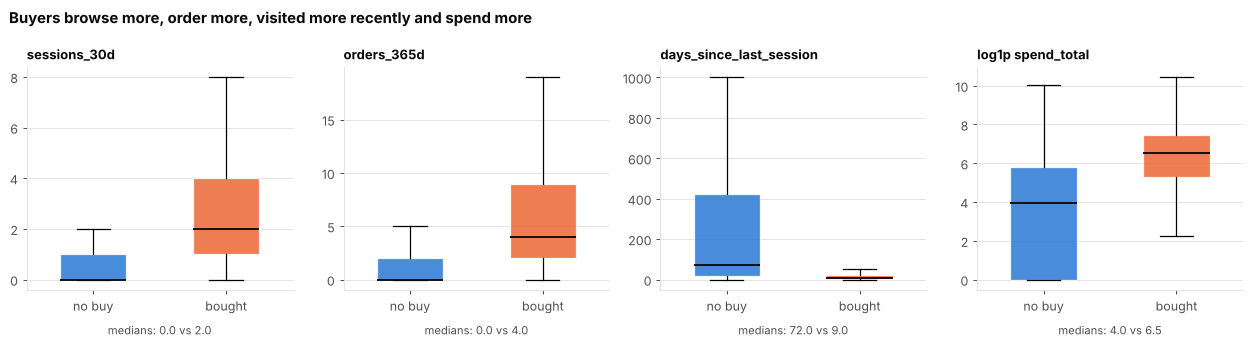

In [19]:
box_cols = [("sessions_30d", False), ("orders_365d", False), ("days_since_last_session", False), ("spend_total", True)]
fig, axes = plt.subplots(1, 4, figsize=(14, 4))
for ax, (col, logy) in zip(axes, box_cols):
    data = [train.loc[train.target == 0, col], train.loc[train.target == 1, col]]
    if logy: data = [np.log1p(d) for d in data]
    bp = ax.boxplot(data, widths=0.5, patch_artist=True, showfliers=False, medianprops=dict(color=INK, lw=1.5))
    for patch, c in zip(bp["boxes"], [NONBUYER, BUYER]):
        patch.set_facecolor(c); patch.set_alpha(0.85); patch.set_edgecolor("white")
    ax.set_xticks([1, 2], ["no buy", "bought"])
    med = [np.median(d) for d in data]
    ax.set_title(f"{'log1p ' if logy else ''}{col}", fontsize=10.5)
    ax.text(0.5, -0.2, f"medians: {med[0]:.1f} vs {med[1]:.1f}", transform=ax.transAxes, ha="center", color=INK2, fontsize=9)
fig.suptitle("Buyers browse more, order more, visited more recently and spend more", x=0.01, ha="left", fontweight="bold", color=INK)
fig.tight_layout(); save(fig, "c12_boxplots_by_target")

**Finding:** The middle half of buyers (the boxes) barely overlaps with non-buyers on `sessions_30d` and `orders_365d`. The medians tell the story: buyers had **2 sessions** in the last 30 days (non-buyers: 0), **4 orders** in the last year (non-buyers: 0), and last visited **9 days** before the cutoff (non-buyers: 72 days). Buyers also spent more in total (median \$694 vs \$51), but the spend boxes overlap more than the activity boxes, so *how recently* someone was active separates better than *how much* they spent.

**Decision:** Recent-activity counts are the core inputs. Outliers above the whiskers (hidden here) are real heavy users, not errors, so they're kept and handled by `log1p`, not removed.

### 4.5 Missing values

,% missing
avg_csat,85.6


,rate,n
csat_status,,
no tickets,11.4%,"49,018"
"tickets, no rating",21.8%,"5,782"
rated,26.9%,"9,200"


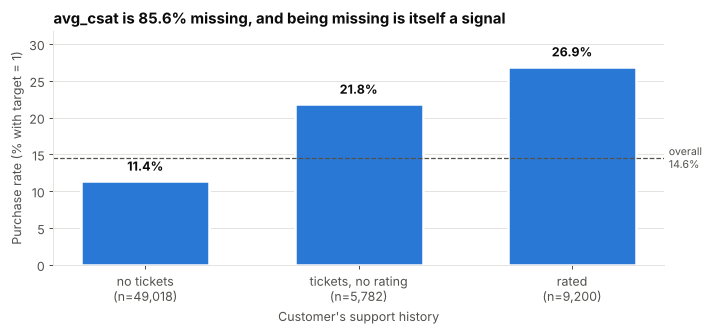

In [20]:
miss = train.isna().mean().mul(100).round(1)
miss = miss[miss > 0].sort_values(ascending=False)
display(miss.rename("% missing").to_frame())
csat = train.assign(csat_status=np.where(train.tickets_total == 0, "no tickets", np.where(train.avg_csat.isna(), "tickets, no rating", "rated")))
cs = purchase_rate(csat, "csat_status").loc[["no tickets", "tickets, no rating", "rated"]]
display(cs.style.format({"rate": "{:.1%}", "n": "{:,}"}))
fig, ax = plt.subplots(figsize=(8, 3.8))
rate_bars(ax, cs, "avg_csat is 85.6% missing, and being missing is itself a signal", "Customer's support history", OVERALL)
fig.tight_layout(); save(fig, "c13_missing_csat")

**Finding:** Only **`avg_csat` has missing values: 85.6%**. Most of that (76.6% of customers) is because the customer never opened a ticket. The rest opened tickets but never gave a rating. The missingness isn't random: customers with no tickets buy at 11.4%, while those who rated buy at 26.9% (they're more engaged customers).

**Decision:** Don't drop `avg_csat` and don't fill it with 0 (that would mean "very unhappy"). Instead: fill it with the **training-split median** and add an **`avg_csat_missing` flag**, so the MLP knows the value was invented. This is done inside the pipeline (Section 8) so the median comes from training rows only.

## 5. Relationships between features

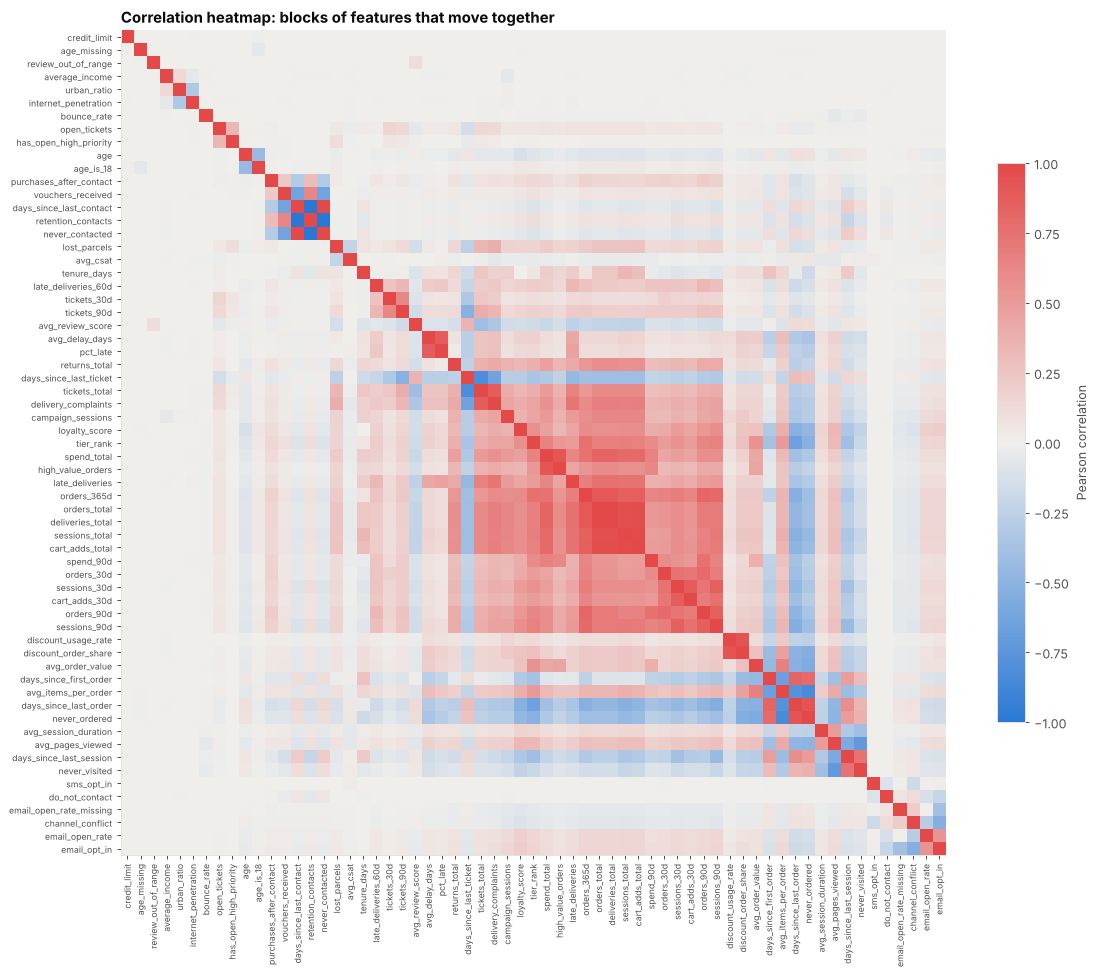

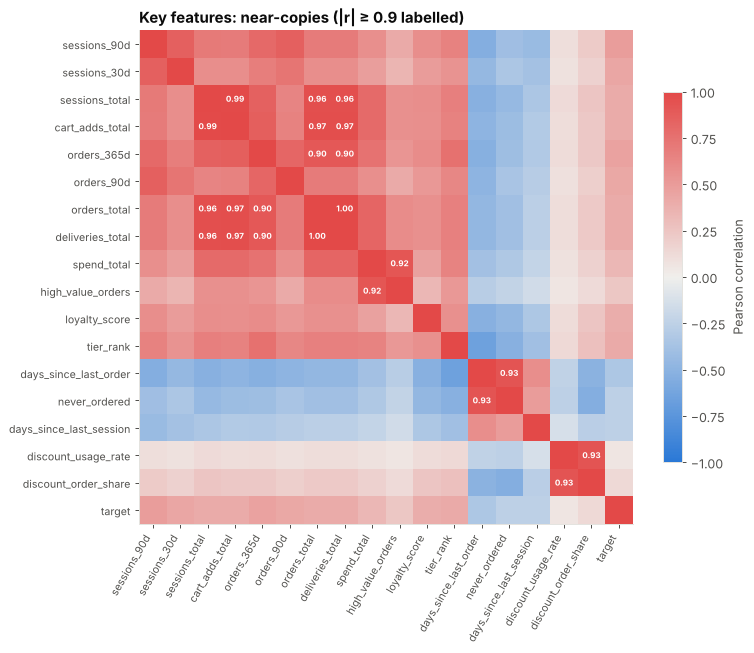

,feature A,feature B,r
0,retention_contacts,never_contacted,-1.000
1,orders_total,deliveries_total,1.000
2,days_since_last_contact,never_contacted,1.000
3,days_since_last_contact,retention_contacts,-1.000
4,sessions_total,cart_adds_total,0.985
5,deliveries_total,cart_adds_total,0.966
6,orders_total,cart_adds_total,0.966
7,deliveries_total,sessions_total,0.958
8,orders_total,sessions_total,0.958
9,discount_usage_rate,discount_order_share,0.929


In [21]:
corr = train[num_cols].corr()
# order features so that related ones sit next to each other (simple clustering on 1 - |r|)
from scipy.cluster.hierarchy import linkage, leaves_list
from scipy.spatial.distance import squareform
dist = 1 - corr.abs().fillna(0).values
np.fill_diagonal(dist, 0)
ordr = leaves_list(linkage(squareform(dist, checks=False), "average"))
cm = corr.iloc[ordr, ordr]
fig, ax = plt.subplots(figsize=(13, 11.5))
im = ax.imshow(cm.values, cmap=DIVERGING, vmin=-1, vmax=1)
ax.set_xticks(range(len(cm)), cm.columns, rotation=90, fontsize=7); ax.set_yticks(range(len(cm)), cm.index, fontsize=7)
ax.grid(False)
cb = fig.colorbar(im, ax=ax, shrink=0.6); cb.set_label("Pearson correlation")
ax.set_title("Correlation heatmap: blocks of features that move together")
fig.tight_layout(); save(fig, "c14_correlation_heatmap")

# compact version for the slides: the 16 features most related to the target, plus their twins
key = ["sessions_90d", "sessions_30d", "sessions_total", "cart_adds_total", "orders_365d", "orders_90d", "orders_total",
       "deliveries_total", "spend_total", "high_value_orders", "loyalty_score", "tier_rank", "days_since_last_order",
       "never_ordered", "days_since_last_session", "discount_usage_rate", "discount_order_share", "target"]
ck = train[key].corr()
fig, ax = plt.subplots(figsize=(8.6, 7.4))
im = ax.imshow(ck.values, cmap=DIVERGING, vmin=-1, vmax=1); ax.grid(False)
ax.set_xticks(range(len(key)), key, rotation=60, ha="right", fontsize=8.5); ax.set_yticks(range(len(key)), key, fontsize=8.5)
for i in range(len(key)):
    for j in range(len(key)):
        v = ck.values[i, j]
        if i != j and abs(v) >= 0.9:
            ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=6.5, color="white", fontweight="bold")
fig.colorbar(im, ax=ax, shrink=0.7).set_label("Pearson correlation")
ax.set_title("Key features: near-copies (|r| ≥ 0.9 labelled)")
fig.tight_layout(); save(fig, "c14b_correlation_key_features")

pairs = cm.where(np.triu(np.ones(cm.shape, dtype=bool), 1)).stack()
high = pairs[pairs.abs() >= 0.9].sort_values(key=abs, ascending=False).rename("r").reset_index()
high.columns = ["feature A", "feature B", "r"]
display(high.round(3))

**Finding:** The heatmap shows clear **blocks**: an activity block (orders, sessions, cart adds, deliveries), a recency block (the `days_since_*` columns with the `never_*` flags) and a support block (tickets, complaints). Inside them, several pairs are near-copies:
- `orders_total` = `deliveries_total` (r = 1.00): every order has exactly one delivery, so they're the **same number**.
- `retention_contacts`, `days_since_last_contact` and `never_contacted` (|r| = 1.00): only one contact per customer existed, so all three say "contacted or not".
- `sessions_total` vs `cart_adds_total` (0.985), `discount_usage_rate` vs `discount_order_share` (0.93), `days_since_last_order` vs `never_ordered` (0.93, because of the 1100 sentinel).

**Decision:** **Drop the exact duplicates** (`deliveries_total`, `retention_contacts`, `never_contacted`), since they add nothing. **Keep the near-copies for the MLP**: neural networks handle correlated inputs, and L2 regularisation/dropout stop it relying on one twin. This *would* matter for logistic regression (unstable coefficients) and for explaining the model, so when we explain predictions later we'll group twin features together (e.g. "activity" instead of `sessions_total` vs `cart_adds_total`).

## 6. Hypotheses and the brief's claims
Our project plan listed hypotheses to check against the data. Here are the results.
### 6.1 "One in three customers haven't visited in the last 90 days" (the brief, section 3)

No session in last 90 days: 40.1% (32,086 customers)


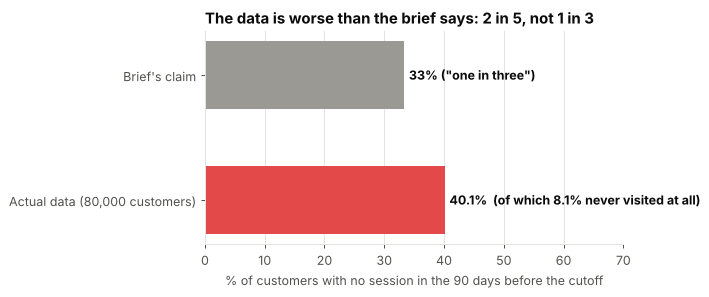

In [22]:
allf = pd.read_csv(FEAT / "features.csv", usecols=["customer_id", "sessions_90d", "never_visited"])
inactive = (allf.sessions_90d == 0).mean()
never = allf.never_visited.mean()
fig, ax = plt.subplots(figsize=(7.5, 3.4))
ax.barh(["Brief's claim", "Actual data (80,000 customers)"], [100 / 3, inactive * 100], color=[GRAY, RED], height=0.55)
ax.text(100 / 3 + 0.8, 0, "33% (\"one in three\")", va="center", color=INK, fontweight="bold")
ax.text(inactive * 100 + 0.8, 1, f"{inactive:.1%}  (of which {never:.1%} never visited at all)", va="center", color=INK, fontweight="bold")
ax.set_xlim(0, 70); ax.set_xlabel("% of customers with no session in the 90 days before the cutoff"); ax.grid(axis="x"); ax.grid(axis="y", visible=False)
ax.set_title("The data is worse than the brief says: 2 in 5, not 1 in 3")
ax.invert_yaxis(); fig.tight_layout(); save(fig, "c15_brief_claim_inactive")
print(f"No session in last 90 days: {inactive:.1%} ({(allf.sessions_90d == 0).sum():,} customers)")

**Finding:** **40.1% of customers** (32,000+) had no session in the last 90 days, not "one in three" (33%). 8.1% have *never* visited. The leadership team is underestimating the problem by about 7 percentage points.

**Decision:** Present this in PR1 as a correction to the brief. It also sizes the win-back pool: 4 in 10 customers are dormant, and they buy at only a few percent, so the model's job is to find the few dormant customers worth a nudge.

### 6.2 Do late or lost deliveries lower future purchases? (Operations' suspicion)

,rate,n
delivery_experience,,
never late,16.4%,"26,270"
late before,30.3%,"11,542"
late in last 60 days,43.6%,"1,548"


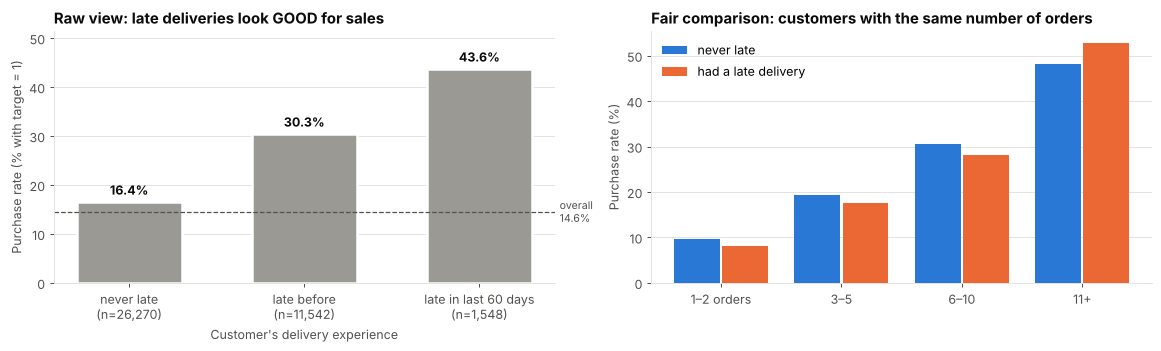

ever_late,had a late delivery,never late
orders_band,,
1–2 orders,8.1%,9.6%
3–5,17.5%,19.3%
6–10,28.1%,30.5%
11+,52.8%,48.2%


In [23]:
has_del = train[train.deliveries_total > 0].copy()
has_del["delivery_experience"] = np.where(has_del.late_deliveries_60d > 0, "late in last 60 days", np.where(has_del.late_deliveries > 0, "late before", "never late"))
d1 = purchase_rate(has_del, "delivery_experience").loc[["never late", "late before", "late in last 60 days"]]
display(d1.style.format({"rate": "{:.1%}", "n": "{:,}"}))
has_del["orders_band"] = pd.cut(has_del.orders_total, [0, 2, 5, 10, np.inf], labels=["1–2 orders", "3–5", "6–10", "11+"])
has_del["ever_late"] = np.where(has_del.late_deliveries > 0, "had a late delivery", "never late")
ctrl = has_del.pivot_table(index="orders_band", columns="ever_late", values="target", aggfunc="mean", observed=True)
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
rate_bars(axes[0], d1, "Raw view: late deliveries look GOOD for sales", "Customer's delivery experience", OVERALL, color=GRAY)
x = np.arange(len(ctrl))
axes[1].bar(x - 0.2, ctrl["never late"] * 100, 0.38, color=BLUE, label="never late")
axes[1].bar(x + 0.2, ctrl["had a late delivery"] * 100, 0.38, color=ORANGE, label="had a late delivery")
axes[1].set_xticks(x, ctrl.index); axes[1].set_ylabel("Purchase rate (%)"); axes[1].legend()
axes[1].set_title("Fair comparison: customers with the same number of orders")
fig.tight_layout(); save(fig, "c16_late_delivery_confounding")
display(ctrl.style.format("{:.1%}"))

**Finding:** At first glance, customers with a late delivery buy *more* (43.6% vs 16.4%). That's **confounding**: frequent buyers get more deliveries, so they're more likely to have had one late. When customers with the **same number of orders** are compared (right), the picture **reverses**: for customers with 1–10 orders, a late delivery goes with a purchase rate **1.5–2.4 points lower** (8.1% vs 9.6%, 17.5% vs 19.3%, 28.1% vs 30.5%). Only the heaviest buyers (11+ orders) don't show it. This is **Simpson's paradox**: the overall comparison points the wrong way.

**Decision:** Operations' suspicion gets **weak support**: late deliveries are linked to slightly fewer repeat purchases once order volume is held constant. This is still a correlation, not proof of cause. Keep the delivery features (`pct_late`, `late_deliveries_60d`, `lost_parcels`) as model inputs, and the MLP should learn the interaction with order volume. Don't show a raw "late customers buy more" chart to staff; it would mislead them.

### 6.3 Past vouchers, and other hypotheses from the project plan

In [24]:
vou = train.assign(voucher=np.where(train.never_contacted == 1, "never contacted", np.where(train.vouchers_received > 0, "got a voucher", "contacted, no voucher")))
vr = purchase_rate(vou, "voucher").loc[["never contacted", "contacted, no voucher", "got a voucher"]]
display(vr.style.format({"rate": "{:.1%}", "n": "{:,}"}))
contacts = rch.merge(pd.read_csv(CLEAN / "customer_preferences_clean.csv"), on="customer_id", how="left")
tk = tick_cl[["customer_id", "created_date", "category"]].assign(created_date=lambda d: pd.to_datetime(d.created_date))
near = contacts[["contact_id", "customer_id", "contact_date"]].assign(contact_date=lambda d: pd.to_datetime(d.contact_date)).merge(tk, on="customer_id")
near["gap"] = (near.contact_date - near.created_date).dt.days
h = pd.DataFrame([
    ("H1", "Recency predicts October purchase", "Supported: 40.8% → 2.6% (Section 3.1)"),
    ("H2", "Contacts landed within days of a ticket",
     f"Supported: {near[(near.gap >= 0) & (near.gap <= 7)].contact_id.nunique()} contacts within 7 days after a ticket, {near[near.gap == 0].contact_id.nunique()} on the same day"),
    ("H3", "Past offers broke tier eligibility", "Supported: 195 contacts (Section 1.5)"),
    ("H4", "Contacts went to do-not-contact or opted-out customers",
     f"Not supported: {int((contacts.do_not_contact == 1).sum())} to do-not-contact, {int(((contacts.channel == 'email') & (contacts.email_opt_in == 0)).sum())} emails to opt-outs, {int(((contacts.channel == 'sms') & (contacts.sms_opt_in == 0)).sum())} SMS to opt-outs"),
    ("H5", "Late or lost deliveries lower purchases", "Weak support once order volume is held constant: 1.5–2.4 points lower (Simpson's paradox, Section 6.2)"),
    ("H6", "Voucher recipients buy anyway", f"Partly: {vr.loc['got a voucher', 'rate']:.1%} vs {vr.loc['never contacted', 'rate']:.1%}, but they were picked by recency (selection bias)"),
    ("H7", "'One in three inactive for 90 days'", "Wrong: it's 40.1% (Section 6.1)"),
], columns=["#", "hypothesis", "result"])
display(h)

,rate,n
voucher,,
never contacted,13.7%,"56,818"
"contacted, no voucher",20.1%,"4,114"
got a voucher,22.6%,"3,068"


,#,hypothesis,result
0,H1,Recency predicts October purchase,Supported: 40.8% → 2.6% (Section 3.1)
1,H2,Contacts landed within days of a ticket,"Supported: 37 contacts within 7 days after a ticket, 6 on the same day"
2,H3,Past offers broke tier eligibility,Supported: 195 contacts (Section 1.5)
3,H4,Contacts went to do-not-contact or opted-out customers,"Not supported: 0 to do-not-contact, 0 emails to opt-outs, 0 SMS to opt-outs"
4,H5,Late or lost deliveries lower purchases,"Weak support once order volume is held constant: 1.5–2.4 points lower (Simpson's paradox, Section 6.2)"
5,H6,Voucher recipients buy anyway,"Partly: 22.6% vs 13.7%, but they were picked by recency (selection bias)"
6,H7,'One in three inactive for 90 days',Wrong: it's 40.1% (Section 6.1)


**Finding:** 5 of 7 hypotheses are supported, at least partly. H4 is not supported, and H7 is wrong in the other direction. Two stand out for the agent:
- **H2:** 37 win-back contacts went out within a week of a support ticket, 6 on the same day. That's the Customer Service Lead's "lost parcel + 10% off" complaint, confirmed in the data.
- **H4:** consent rules **were** followed (0 breaches). The policy problem is tier eligibility (H3), not consent.

**Decision:** The agent's policy check must include "no contact within N days of an open or recent ticket" and tier eligibility. Voucher effects can't be judged from this data, because vouchers weren't randomly assigned, so the model predicts purchase, not voucher uplift.

## 7. Fairness and train/test checks
### 7.1 Purchase rate by country and age group (Ethical AI checklist, Q9)

Country range: 13.8% – 15.0%; age-group range: 11.2% – 17.8%


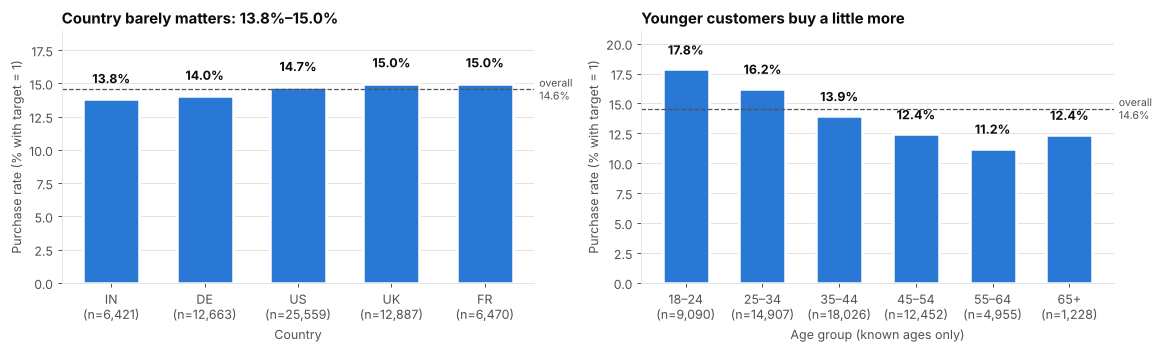

In [25]:
ctry = purchase_rate(train, "country_code").sort_values("rate")
train["age_group"] = pd.cut(train.age, [17, 24, 34, 44, 54, 64, 100], labels=["18–24", "25–34", "35–44", "45–54", "55–64", "65+"])
ag = purchase_rate(train[train.age_missing == 0], "age_group")
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
rate_bars(axes[0], ctry, "Country barely matters: 13.8%–15.0%", "Country", OVERALL)
rate_bars(axes[1], ag, "Younger customers buy a little more", "Age group (known ages only)", OVERALL)
fig.tight_layout(); save(fig, "c17_fairness_country_age")
print(f"Country range: {ctry.rate.min():.1%} – {ctry.rate.max():.1%}; age-group range: {ag.rate.min():.1%} – {ag.rate.max():.1%}")

**Finding:** All five countries buy at **13.8%–15.0%**, so there's no meaningful country difference in the data. Age shows a gentle slope (17.8% for 18–24 down to 11.2% for 55–64).

**Decision:** Country is a weak predictor, so the model has little reason to treat countries differently. That's a good fairness sign, and we'll **check the trained model's recall and precision per country and per age group** (Ethical AI Q9) to confirm it doesn't introduce a bias the data doesn't have. Because each country has its own retention budget, the agent will rank customers *within* each country rather than globally.

### 7.2 Is the test set like the training set?

In [26]:
drift = ((train[num_cols].mean() - test[num_cols].mean()) / train[num_cols].std()).abs().sort_values(ascending=False)
print("Largest difference between train and test means (in standard deviations):")
display(drift.head(5).round(3).rename("|SMD| train vs test").to_frame())
print("Country mix, train vs test:")
display(pd.concat([train.country_code.value_counts(normalize=True), test.country_code.value_counts(normalize=True)], axis=1, keys=["train", "test"]).round(3))

Largest difference between train and test means (in standard deviations):
Country mix, train vs test:


,|SMD| train vs test
orders_90d,0.021
bounce_rate,0.020
spend_90d,0.019
do_not_contact,0.019
cart_adds_30d,0.018


,train,test
country_code,,
US,0.399,0.400
UK,0.201,0.199
DE,0.198,0.197
FR,0.101,0.102
IN,0.100,0.102


**Finding:** No feature differs between train and test by more than **0.02 standard deviations**, and the country mix is the same. The test set was drawn from the same population.

**Decision:** A stratified validation split from `train_features` will give a reliable estimate of test performance, so no reweighting or drift correction is needed.

## 8. Data preparation for the MLP: every decision in one pipeline

| EDA finding | Section | Preparation step |
|---|---|---|
| Only 14.6% buy | 2 | Stratified split; class weight ≈ 5.9; PR-AUC/F1 as metrics |
| Exact duplicate features | 5 | Drop `deliveries_total`, `retention_contacts`, `never_contacted`; drop IDs and text (`region`) |
| Skewed money/count columns | 4.1 | `log1p`, then scale |
| 1100 sentinel and other spikes | 4.2, 4.3 | Keep `never_*`, `age_missing`, `age_is_18` flags; robust scaling |
| `avg_csat` 85.6% missing | 4.5 | Training-split median + `avg_csat_missing` flag |
| Tier is ordered | 3.3 | Use `tier_rank`, drop `customer_tier` text |
| Few categories | 3.3, 7.1 | One-hot `country_code`, `preferred_channel`, `preferred_language`, `region_tier` |
| Recency is the current rule | 3.1 | Recency-only baseline to beat |

The pipeline is **fitted on the training split only**, then applied to validation and test, so no information leaks from validation into the scaling or imputation.

In [27]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder, RobustScaler, StandardScaler
from sklearn.impute import SimpleImputer

DROP = ["customer_id", "target", "region", "customer_tier", "deliveries_total", "retention_contacts", "never_contacted",
        "recency_bucket", "sessions_30d_bucket", "age_group"]
CATEGORICAL = ["country_code", "preferred_channel", "preferred_language", "region_tier"]
BINARY = [c for c in num_cols if set(train[c].dropna().unique()) <= {0, 1} and c not in DROP]
LOG_SKEWED = [c for c in num_cols if c not in DROP + BINARY and (train[c] >= 0).all() and train[c].skew() > 2]
SENTINEL_COLS = [c for c in day_cols if c not in DROP]
OTHER_NUM = [c for c in num_cols if c not in DROP + BINARY + LOG_SKEWED + SENTINEL_COLS + ["avg_csat"]]

def add_csat_flag(df):
    df = df.copy(); df["avg_csat_missing"] = df["avg_csat"].isna().astype(int); return df

prep = ColumnTransformer([
    ("log_scale", Pipeline([("log1p", FunctionTransformer(np.log1p, feature_names_out="one-to-one")), ("scale", StandardScaler())]), LOG_SKEWED),
    ("sentinel_days", RobustScaler(), SENTINEL_COLS),
    ("numeric", StandardScaler(), OTHER_NUM),
    ("csat", Pipeline([("median", SimpleImputer(strategy="median")), ("scale", StandardScaler())]), ["avg_csat"]),
    ("flags", "passthrough", BINARY + ["avg_csat_missing"]),
    ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False), CATEGORICAL),
], verbose_feature_names_out=False)

# The team's ONE shared split (70/15/15, stratified, seed 42) from data_prep.get_splits, so every
# member's model is trained and scored on exactly the same customers. Don't make a new split here.
labelled = pd.read_csv(FEAT / "train_features.csv")
tr_part, val_part, te_part = get_splits(labelled)
X_tr, y_tr = add_csat_flag(tr_part), tr_part["target"]
X_val, y_val = add_csat_flag(val_part), val_part["target"]
X_te, y_te = add_csat_flag(te_part), te_part["target"]

X_tr_p = prep.fit_transform(X_tr)          # fitted on the training split ONLY
X_val_p = prep.transform(X_val)
X_te_p = prep.transform(X_te)              # team test split: used once, at the very end of modelling
X_sub_p = prep.transform(add_csat_flag(test))   # test_features.csv: the 16,000 unlabelled customers to submit
feature_names = prep.get_feature_names_out()

print(f"Groups: {len(LOG_SKEWED)} log-scaled, {len(SENTINEL_COLS)} sentinel day columns, {len(OTHER_NUM)} other numeric, "
      f"1 csat, {len(BINARY) + 1} flags, {len(CATEGORICAL)} categoricals one-hot encoded")
print(f"MLP input width: {X_tr_p.shape[1]} features")
print(f"Train {X_tr_p.shape}, validation {X_val_p.shape}, test {X_te_p.shape}, submission {X_sub_p.shape}")
print(f"Buy rate — train {y_tr.mean():.2%}, validation {y_val.mean():.2%}, test {y_te.mean():.2%}")
print("Missing values after preparation:", int(sum(np.isnan(a).sum() for a in (X_tr_p, X_val_p, X_te_p, X_sub_p))))
print(f"Positive-class weight for the loss: {(y_tr == 0).sum() / (y_tr == 1).sum():.2f}")
print("Log-scaled columns:", LOG_SKEWED)

Groups: 26 log-scaled, 5 sentinel day columns, 14 other numeric, 1 csat, 15 flags, 4 categoricals one-hot encoded
MLP input width: 77 features
Train (44800, 77), validation (9600, 77), test (9600, 77), submission (16000, 77)
Buy rate — train 14.57%, validation 14.57%, test 14.57%
Missing values after preparation: 0
Positive-class weight for the loss: 5.86
Log-scaled columns: ['orders_total', 'spend_total', 'avg_order_value', 'orders_30d', 'orders_90d', 'orders_365d', 'spend_90d', 'high_value_orders', 'sessions_total', 'sessions_30d', 'sessions_90d', 'avg_session_duration', 'cart_adds_total', 'cart_adds_30d', 'bounce_rate', 'campaign_sessions', 'late_deliveries', 'lost_parcels', 'returns_total', 'avg_delay_days', 'late_deliveries_60d', 'pct_late', 'tickets_total', 'tickets_30d', 'tickets_90d', 'delivery_complaints']


### 8.1 Check: did the preparation do what the EDA asked for?

In [28]:
P = pd.DataFrame(X_tr_p, columns=feature_names)
summary = pd.DataFrame({"mean": P.mean(), "std": P.std(), "skew": P.skew()}).round(2)
cont = [c for c in feature_names if c in LOG_SKEWED + OTHER_NUM + ["avg_csat"]]
print("Continuous inputs after preparation — mean range:", summary.loc[cont, "mean"].min(), "to", summary.loc[cont, "mean"].max(),
      "| std range:", summary.loc[cont, "std"].min(), "to", summary.loc[cont, "std"].max())
print("Largest remaining skew among log-scaled inputs:", summary.loc[LOG_SKEWED, "skew"].abs().max())
before_after = pd.DataFrame({"skew before": train[LOG_SKEWED].skew().round(2), "skew after": summary.loc[LOG_SKEWED, "skew"]})
display(before_after.sort_values("skew before", ascending=False).head(10))

# save the prepared splits for the model notebook (data/processed is git-ignored, so rerun this to recreate them)
import joblib
OUT = FEAT / "mlp_prepared"
OUT.mkdir(parents=True, exist_ok=True)
for name, Xp, part in [("train", X_tr_p, tr_part), ("val", X_val_p, val_part), ("test", X_te_p, te_part)]:
    pd.DataFrame(Xp, columns=feature_names).assign(customer_id=part.customer_id.values, target=part.target.values).to_csv(OUT / f"{name}_prepared.csv", index=False)
pd.DataFrame(X_sub_p, columns=feature_names).assign(customer_id=test.customer_id.values).to_csv(OUT / "submission_prepared.csv", index=False)
joblib.dump(prep, OUT / "mlp_preprocessor.joblib")      # the fitted pipeline, to transform new customers the same way
print("Saved prepared data and the fitted preprocessor to", OUT.relative_to(ROOT).as_posix())

Continuous inputs after preparation — mean range: -0.0 to -0.0 | std range: 1.0 to 1.0
Largest remaining skew among log-scaled inputs: 12.39
Saved prepared data and the fitted preprocessor to data/processed/mlp_prepared


,skew before,skew after
avg_session_duration,19.41,-2.80
bounce_rate,16.01,12.39
high_value_orders,9.48,2.53
tickets_30d,8.10,7.96
lost_parcels,8.08,7.22
spend_total,7.31,-0.11
late_deliveries_60d,6.90,6.46
spend_90d,6.34,1.16
tickets_90d,5.09,4.74
campaign_sessions,5.08,1.52


**Finding:** All continuous inputs now have mean ≈ 0 and standard deviation ≈ 1, there are no missing values left, and the validation split keeps the 14.6% buy rate. The log transform fixed the money and activity columns (`spend_total` 7.3 → −0.1, `avg_session_duration` 19.4 → −2.8). A few columns stay skewed (`bounce_rate`, `tickets_30d`, `lost_parcels`) because almost everyone has 0. Their skew comes from rare non-zero values, not from huge ones, so no transform can remove it; they behave almost like 0/1 flags, which an MLP handles fine.

## Summary: what the EDA tells the model
1. **The target is rare (14.6%).** Use PR-AUC and F1, class weight ≈ 5.9 and a tuned threshold. Accuracy is misleading.
2. **Recency is strong (40.8% → 2.6%) but it's the CRM team's existing rule.** The MLP must beat a recency-only baseline.
3. **Browsing adds what recency misses** (4.3% → 71.8% by sessions, inside every recency bucket). This justifies combining 8 data sources. Benchmarks to beat: recency alone **PR-AUC 0.373**, simple logistic regression **0.538**.
4. **Data problems were found and fixed:** 15 country spellings, 904 duplicate orders, 579 $0 orders, 1,484 sessions over 4 hours, and **510 future delivery dates (leakage)**.
5. **Artificial values are flagged, not hidden:** the 1100 sentinel, ages 18 and 38, and 85.6% missing `avg_csat` (missingness is informative).
6. **Exact duplicate features are dropped**, and near-copies are kept for the MLP but grouped when explaining it.
7. **The brief underestimates inactivity** (40.1%, not 33%). **195 past offers broke tier policy**, and **37 contacts followed a ticket within a week**: evidence for the agent's policy checks. Late deliveries look good for sales until order volume is held constant, then slightly bad (**Simpson's paradox**).
8. **Country barely affects buying (13.8%–15.0%)**, a good fairness sign to re-check on the trained model.